In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp

At B_0 = 1.0 whales, the Population reaches it's B_{MSY} after 238 years.
At B_0 = 715.0 whales, the Population reaches it's B_{MSY} after 107 years.
At B_0 = 1429.0 whales, the Population reaches it's B_{MSY} after 93 years.
At B_0 = 2143.0 whales, the Population reaches it's B_{MSY} after 85 years.
At B_0 = 2857.0 whales, the Population reaches it's B_{MSY} after 79 years.
At B_0 = 3571.0 whales, the Population reaches it's B_{MSY} after 74 years.
At B_0 = 4285.0 whales, the Population reaches it's B_{MSY} after 71 years.
At B_0 = 4999.0 whales, the Population reaches it's B_{MSY} after 67 years.


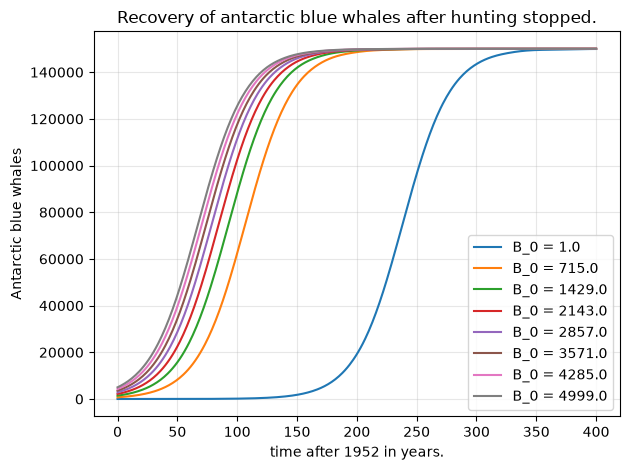

In [2]:
alpha = 0.05
beta = alpha/150000
B0 = np.linspace(1,4999,8)
Y = 0
def func(t,B,alpha,beta,Y):
    return ((alpha-beta*B)*B-Y)
t_end = 400
t_span = [0,t_end]
t_eval = np.linspace(0, t_end, t_end+1)
sol = solve_ivp(func,t_span,B0,t_eval=t_eval,args = (alpha,beta,Y))
for i,j in enumerate(B0):
    population = sol.y[i]
    index = np.argmin(np.abs(population - 75000))
    plt.plot(sol.t,population,label = f"B_0 = {j}")
    print(rf"At B_0 = {j} whales, the Population reaches it's B_{{MSY}} after {index} years.")
    plt.xlabel("time after 1952 in years.")
    plt.ylabel("Antarctic blue whales")
    plt.title("Recovery of antarctic blue whales after hunting stopped.")
    plt.legend()
    plt.grid(True,alpha=0.3)
    plt.tight_layout()

   year         Y         f         I
0  1944  0.249956  0.220000  1.136163
1  1945  0.534124  0.452298  1.180911
2  1946  0.941921  0.828813  1.136469
3  1947  1.017681  0.798674  1.274214
4  1948  2.321465  1.192880  1.946101
Index(['year', 'Y', 'f', 'I'], dtype='object')
q     = 0.0328741
alpha = 0.808303
beta  = 0.0153273


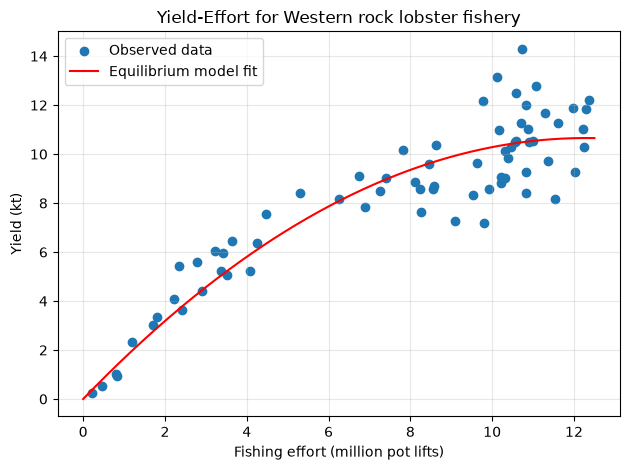

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("Western_rock_lobster.csv")

print(df.head())
print(df.columns)

E = df["f"].to_numpy()
Y = df["Y"].to_numpy()

mask = np.isfinite(E) & np.isfinite(Y)
E = E[mask]
Y = Y[mask]

def effort_func(E, q, alpha, beta):
    return q * E * (alpha - q * E) / beta

p0 = [0.01, 1.0, 0.01]

popt, pcov = curve_fit(effort_func, E, Y, p0=p0, bounds=(0, np.inf), maxfev=100000)

q_est, alpha_est, beta_est = popt

print(f"q     = {q_est:.6g}")
print(f"alpha = {alpha_est:.6g}")
print(f"beta  = {beta_est:.6g}")

E_fit = np.linspace(0, 12.5, 501)
Y_fit = effort_func(E_fit, q_est, alpha_est, beta_est)


plt.scatter(E, Y, label="Observed data")
plt.plot(E_fit, Y_fit, color="red", label="Equilibrium model fit")

plt.xlabel("Fishing effort (million pot lifts)")
plt.ylabel("Yield (kt)")
plt.title("Yield-Effort for Western rock lobster fishery")
plt.legend()
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()